In [33]:
import random
import numpy as np
from lib.data_utils import load_CIFAR10
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [34]:
cifar_dir = 'data/cifar-10-batches-py'
try:
    del x_train, y_train
    del x_test, y_test
    print('clear data')
except:
    pass

x_train, y_train , x_test, y_test = load_CIFAR10(cifar_dir)

print('Training data shape: ', x_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', x_test.shape)
print('Test labels shape: ', y_test.shape)

clear data
Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


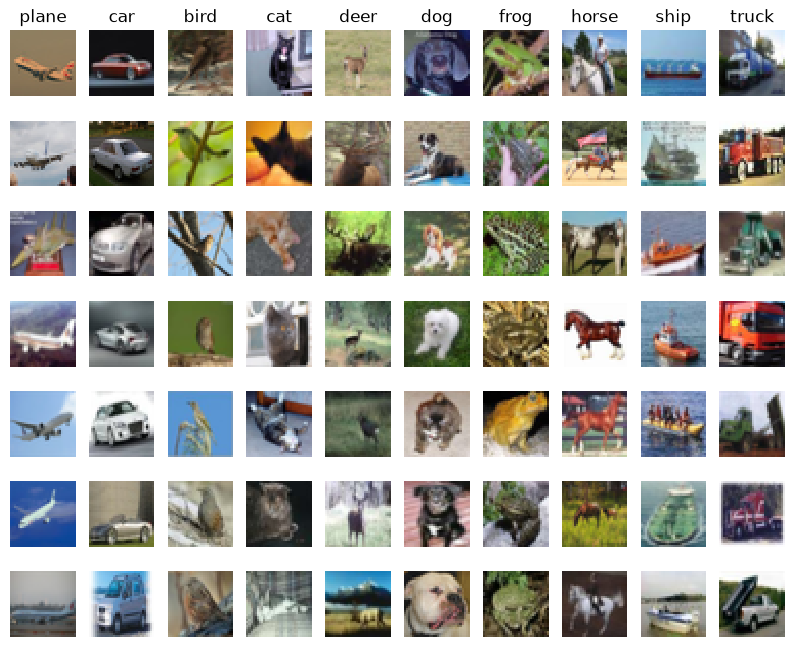

In [30]:
classes = ['plane', 'car','bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
num_class = len(classes)
sample_per_class = 7
for y, cls in enumerate(classes):
    idxs = np.flatnonzero(y_train ==y)
    idxs = np.random.choice(idxs, sample_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt_idx = i * num_class + y + 1
        plt.subplot(sample_per_class, num_class, plt_idx)
        plt.imshow(x_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

In [37]:
num_training = 5000
mask = list(range(num_training))
x_train = x_train[mask]
y_train = y_train[mask]

num_test = 500
mask = list(range(num_test))
x_test = x_test[mask]
y_test = y_test[mask]
print(x_train.shape, x_test.shape)

x_train = np.reshape(x_train, (x_train.shape[0], -1)) #-1 is the remain elements 32x32x3
x_test = np.reshape(x_test, (x_test.shape[0], -1))
print(x_train.shape, x_test.shape)

(5000, 32, 32, 3) (500, 32, 32, 3)
(5000, 3072) (500, 3072)


In [38]:
from lib.k_nearest_neighbor import KNearestNeighbor
classifier = KNearestNeighbor()
classifier.train(x_train, y_train)
 

In [39]:
dists = classifier.compute_distances_two_loops(x_test)
print(dists.shape)

(500, 3072) (5000, 3072)
(500, 5000)


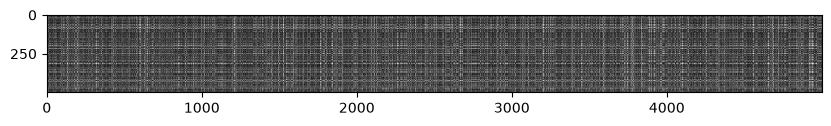

In [16]:
plt.imshow(dists, interpolation='none')
plt.show()

In [40]:
y_test_pred = classifier.predict_labels(dists, k=1)
num_correct = np.sum(y_test_pred == y_test)
accuracy = float(num_correct) /  num_test
print(accuracy)

0.274


In [ ]:
dist_one = classifier.compute_distances_one_loop(x_test)
difference = np.linalg.norm(dists - dist_one, ord='fro')
print('difference: ', difference)

In [41]:
# Let's compare how fast the implementations are
def time_function(f, *args):
    """
    Call a function f with args and return the time (in seconds) that it took to execute.
    """
    import time
    tic = time.time()
    f(*args)
    toc = time.time()
    return toc - tic

two_loop_time = time_function(classifier.compute_distances_two_loops, x_test)
print('Two loop version took %f seconds' % two_loop_time)

one_loop_time = time_function(classifier.compute_distances_one_loop, x_test)
print('One loop version took %f seconds' % one_loop_time)

no_loop_time = time_function(classifier.compute_distances_no_loops, x_test)
print('No loop version took %f seconds' % no_loop_time)


(500, 3072) (5000, 3072)
Two loop version took 81.859763 seconds
One loop version took 71.092788 seconds
No loop version took 0.000098 seconds
